# Pneumonia Detection from Chest X-rays Using CNN
**Dataset:** Kaggle Chest X-ray Pneumonia  
**Task:** Binary classification (NORMAL vs PNEUMONIA)  
**Model:** Convolutional Neural Network (CNN)  
**Metrics:** Accuracy, F1-score, Confusion Matrix  
**Explainability:** Grad-CAM visualization


In [43]:
# 1 Install & Setup
!pip install -q opendatasets matplotlib seaborn


In [44]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input

from sklearn.metrics import classification_report, confusion_matrix, f1_score



# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Download Dataset
We use the Kaggle Chest X-ray Pneumonia dataset.


In [45]:
import opendatasets as od
od.download("https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia")

train_dir = "chest-xray-pneumonia/chest_xray/train"
val_dir   = "chest-xray-pneumonia/chest_xray/val"
test_dir  = "chest-xray-pneumonia/chest_xray/test"


Skipping, found downloaded files in "./chest-xray-pneumonia" (use force=True to force download)


## 3) Image & Training Settings
We use grayscale input.  
Set batch size and epochs for training.


In [46]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 25


## 4) Data Preprocessing and Augmentation
We normalize pixel values and apply augmentations to the training set.


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='grayscale',
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='grayscale',
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='grayscale',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


## 5) Build CNN Model
We create a deep CNN with multiple convolutional blocks, batch normalization, dropout, and a binary classifier.


In [48]:
inputs = Input(shape=(224,224,1))
x = Conv2D(32, (3,3), activation='relu', padding='same')(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(128, (3,3), activation='relu', padding='same', name='last_conv')(x)  # last conv layer
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Conv2D(256, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2,2))(x)

x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,235,329 (50.49 MB)

 Trainable params: 13,234,369 (50.49 MB)

 Non-trainable params: 960 (3.75 KB)

## 6) Callbacks
We use ModelCheckpoint, ReduceLROnPlateau, and EarlyStopping to optimize training.


In [49]:
os.makedirs("models", exist_ok=True)
model_path = "models/finalCNN.keras"

callbacks = [
    ModelCheckpoint(model_path, save_best_only=True, monitor='val_loss', verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', patience=3, factor=0.3, min_lr=1e-6, verbose=1),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)
]


## 7) Train Model
Training the CNN on the training set and validating on the validation set.


In [50]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.8213 - loss: 1.8687
Epoch 1: val_loss improved from inf to 227.26178, saving model to models/finalCNN.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 86s 388ms/step - accuracy: 0.8215 - loss: 1.8623 - val_accuracy: 0.5000 - val_loss: 227.2618 - learning_rate: 0.0010
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.8705 - loss: 0.3041
Epoch 2: val_loss improved from 227.26178 to 152.95947, saving model to models/finalCNN.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 63s 386ms/step - accuracy: 0.8705 - loss: 0.3039 - val_accuracy: 0.5000 - val_loss: 152.9595 - learning_rate: 0.0010
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step - accuracy: 0.8921 - loss: 0.2915
Epoch 3: val_loss improved from 152.95947 to 1.01527, saving model to models/finalCNN.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 60s 369ms/step - accuracy: 0.8921 - loss: 0.2915 - val_accuracy: 0.5625 - val_loss: 1.0153 - learning_rate: 0.0010
Epoch 4/25
163/163 ━━━━━━━

## 8) Evaluate Model
We evaluate on the test set and compute accuracy and F1-score.


In [51]:
model = keras.models.load_model(model_path)

loss, acc = model.evaluate(test_gen, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc*100:.2f}%")

y_pred_prob = model.predict(test_gen)
y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)
y_true = test_gen.classes

f1 = f1_score(y_true, y_pred)
print(f"F1-score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['NORMAL','PNEUMONIA']))


Test Loss: 0.2869
Test Accuracy: 89.74%
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step
F1-score: 0.9208

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.91      0.80      0.85       234
   PNEUMONIA       0.89      0.95      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624



## 9) Confusion Matrix
Visualizing predictions with a heatmap.


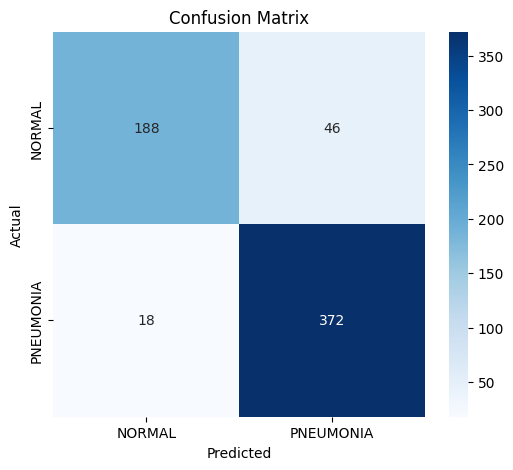

In [52]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['NORMAL','PNEUMONIA'],
            yticklabels=['NORMAL','PNEUMONIA'],
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## 10) Training Curves
Plotting accuracy and loss curves over epochs.


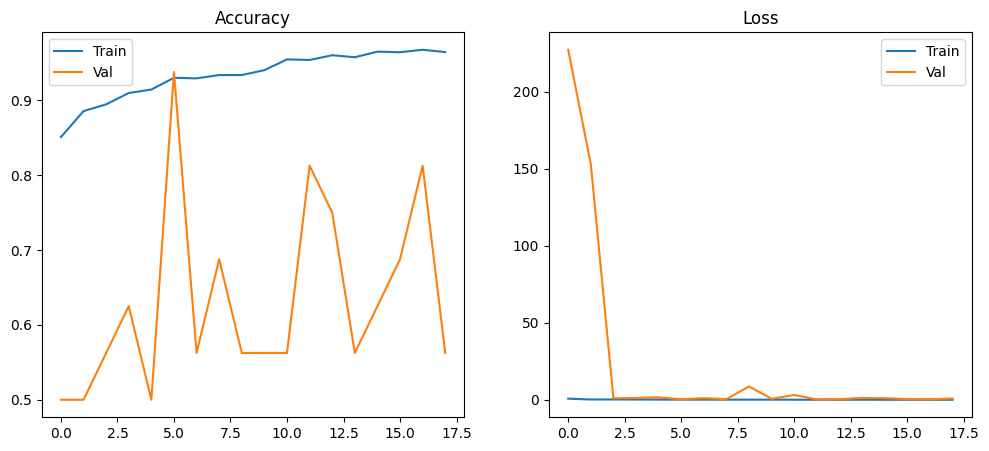

In [53]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()


## 11) Grad-CAM Explainability
Highlight areas of the X-ray that contributed most to the CNN's prediction.


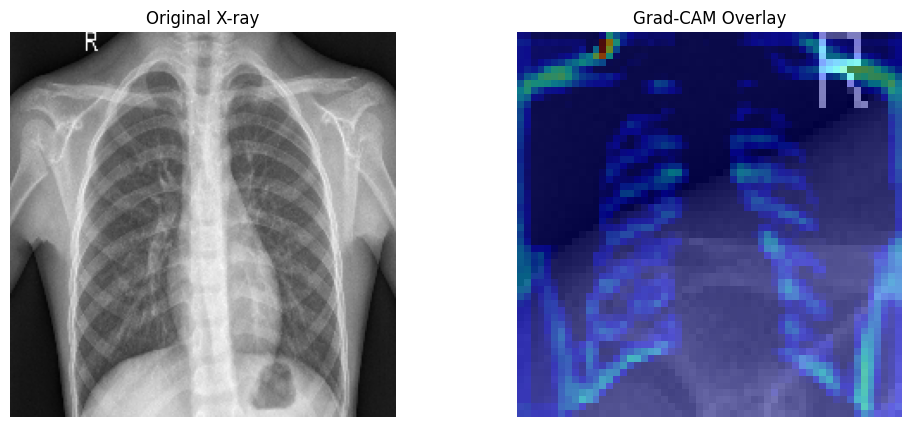

In [62]:
import matplotlib.pyplot as plt

# Example: first test image
img_path = test_gen.filepaths[0]
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, IMAGE_SIZE)
img_array = np.expand_dims(img, axis=(0,-1))/255.0

heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name='last_conv')

plt.figure(figsize=(12,5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original X-ray")
plt.axis('off')

# Heatmap overlay
plt.subplot(1, 2, 2)
plt.imshow(img, cmap='gray')
plt.imshow(heatmap, cmap='jet', alpha=0.5)
plt.title("Grad-CAM Overlay")
plt.axis('off')

plt.show()


## References (CNN)

1. Kaggle Chest X-ray Pneumonia Dataset: [https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia)
2. TensorFlow Documentation: [https://www.tensorflow.org](https://www.tensorflow.org)
3. Keras Documentation: [https://keras.io](https://keras.io)
4. Grad-CAM Paper: [https://arxiv.org/abs/1610.02391](https://arxiv.org/abs/1610.02391)
5. Similar GitHub Project: [https://github.com/inuwamobarak/chest-xray-pneumonia-detection](https://github.com/inuwamobarak/chest-xray-pneumonia-detection)
6. Pneumonia Detection Using Deep Learning (IRJET): [https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf](https://www.irjet.net/archives/V10/i11/IRJET-V10I1191.pdf)